# MBTI Personality Prediction from Social Media Posts

This notebook revisits the original course project and repeats each of its five experiments with three fixes:

1. **Label leakage.** Most users mention their own MBTI type in their posts (for example, "as an INFJ..."),
   so a model can read the answer instead of learning from writing style. Type names and related MBTI terms
   are removed from the text.
2. **Test set used for tuning.** The original notebook chose models and parameters by test accuracy. Here, every
   comparison uses 5-fold cross-validation on the training set, and the test set is used once at the end.
3. **Imbalanced classes.** The largest type (INFP) is about 40 times larger than the smallest (ESTJ), so
   accuracy alone is misleading. Macro F1, which weights all 16 types equally, is the main metric.

| Original experiment | Revised version |
|---|---|
| 1. Compare six models | Section 5: the same models with cross-validation, plus a baseline and Complement Naive Bayes |
| 2. Add SMOTE | Section 6: SMOTE compared with class weights |
| 3. Tune parameters | Section 7: grid search with cross-validation |
| 4. Voting | Section 8: voting with cross-validation |
| 5. Two-level classification | Section 9: temperament group first, then type, with cross-validation |


In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

DATA_PATH = Path('data/mbti.csv')
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid')

# Known harmless warnings: imbalanced-learn using a deprecated scikit-learn API, and spurious
# floating-point warnings from the macOS Accelerate BLAS during matrix multiplication
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*encountered in matmul')

## 1. Data

8,675 users, 16 personality types


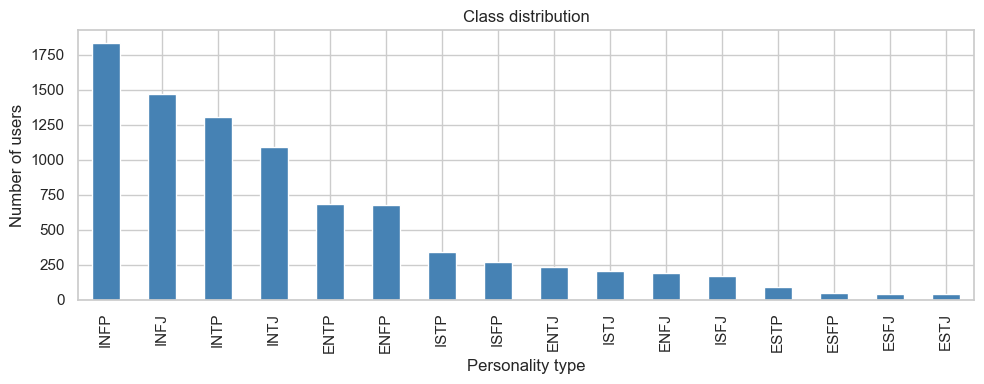

Largest class: INFP (1832), smallest: ESTJ (39)


In [2]:
data = pd.read_csv(DATA_PATH)
print(f'{len(data):,} users, {data.type.nunique()} personality types')

counts = data.type.value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
counts.plot.bar(ax=ax, color='steelblue')
ax.set_xlabel('Personality type')
ax.set_ylabel('Number of users')
ax.set_title('Class distribution')
plt.tight_layout()
fig.savefig(FIG_DIR / 'class_distribution.png', dpi=150)
plt.show()
print(f'Largest class: {counts.index[0]} ({counts.iloc[0]}), smallest: {counts.index[-1]} ({counts.iloc[-1]})')

## 2. Leakage check

How often do users mention an MBTI type, or their own type, in their posts?

In [3]:
TYPES = sorted(data.type.str.lower().unique())
posts_lower = data.posts.str.lower()
mentions_any = posts_lower.str.contains('|'.join(TYPES))
mentions_own = pd.Series([t.lower() in p for t, p in zip(data.type, posts_lower)])
print(f'Users who mention any MBTI type: {mentions_any.mean():.1%}')
print(f'Users who mention their own type: {mentions_own.mean():.1%}')

Users who mention any MBTI type: 96.0%
Users who mention their own type: 90.0%


## 3. Text cleaning

Both versions lowercase the text and remove URLs and non-letter characters. The leak-free version also removes:

- the 16 type names and words that start with them (`infj`, `infjs`, `intjness`, ...)
- partial type patterns with `x` (`inxj`, `xnfp`, ...) and temperament groups (`nf`, `nt`, `sj`, `sp`)
- cognitive-function terms used in MBTI discussions (`ni`, `fe`, `ti-dom`, ...)

In [4]:
URL_RE = re.compile(r'https?://\S+|www\.\S+')
NON_LETTER_RE = re.compile(r'[^a-z\s]')
TYPE_RE = re.compile(r'\b(?:' + '|'.join(TYPES) + r')\w*\b|\b[iex][nsx][tfx][jpx]\w*\b'
                     r'|\b(?:nf|nt|sj|sp|nfs|nts|sjs|sps)\b')
FUNCTION_RE = re.compile(r'\b[nstf][ie](?:\s*(?:dom|aux))?\b')


def clean(text, remove_type_words=True):
    text = URL_RE.sub(' ', text.lower())
    text = NON_LETTER_RE.sub(' ', text)
    if remove_type_words:
        text = TYPE_RE.sub(' ', text)
        text = FUNCTION_RE.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()


data['clean_leaky'] = data.posts.map(lambda t: clean(t, remove_type_words=False))
data['clean'] = data.posts.map(clean)

still_mentions = data.clean.str.contains(r'\b(?:' + '|'.join(TYPES) + r')\b')
print(f'Users whose cleaned text still contains a type name: {still_mentions.mean():.1%}')

Users whose cleaned text still contains a type name: 0.0%


## 4. Train/test split

80/20 stratified split. The test set is not used until the final evaluation. Labels are encoded as integers
because XGBoost requires numeric labels.

In [5]:
train, test = train_test_split(data, test_size=0.2, stratify=data.type, random_state=SEED)
encoder = LabelEncoder().fit(data.type)
y_train = encoder.transform(train.type)
y_test = encoder.transform(test.type)
X_train, X_test = train.clean, test.clean
print(f'Training set: {len(train):,}, test set: {len(test):,}')

# Balanced sample weights for models without a class_weight option (XGBoost)
train_weights = compute_sample_weight('balanced', y_train)

Training set: 6,940, test set: 1,735


## 5. Experiment 1: model comparison

Each model is a pipeline of TF-IDF (5,000 features) and a classifier, so the vectorizer is fitted only on the
training folds. Class imbalance is handled with balanced class weights (sample weights for XGBoost).

The RBF-kernel SVC from the original notebook is left out: it is very slow on 5,000 features and did not
outperform the linear models in the original results.

In [6]:
def make_pipeline(clf, smote=False):
    tfidf = TfidfVectorizer(max_features=5000, stop_words='english',
                            token_pattern=r'\b[a-z]{2,}\b', sublinear_tf=True)
    if smote:
        return ImbPipeline([('tfidf', tfidf), ('smote', SMOTE(random_state=SEED)), ('clf', clf)])
    return Pipeline([('tfidf', tfidf), ('clf', clf)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []      # one row per evaluated model, across all experiments
models = {}       # unfitted estimators, used later to fit the selected model


def evaluate(experiment, name, estimator, sample_weight=False):
    start = time.time()
    params = {'clf__sample_weight': train_weights} if sample_weight else None
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'],
                            params=params)
    results.append({'Experiment': experiment, 'Model': name,
                    'CV accuracy': scores['test_accuracy'].mean(),
                    'CV macro F1': scores['test_f1_macro'].mean(),
                    'Macro F1 std': scores['test_f1_macro'].std()})
    models[name] = (estimator, sample_weight)
    print(f'{name}: macro F1 {scores["test_f1_macro"].mean():.3f} ({time.time() - start:.0f}s)')


def show(experiment):
    table = pd.DataFrame([r for r in results if r['Experiment'] == experiment]).drop(columns='Experiment')
    return table.sort_values('CV macro F1', ascending=False, ignore_index=True).round(3)


def xgb_model(**params):
    return XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.3, tree_method='hist',
                         n_jobs=-1, random_state=SEED, **params)


E1 = '1. Model comparison'
evaluate(E1, 'Most frequent class', make_pipeline(DummyClassifier(strategy='most_frequent')))
evaluate(E1, 'Complement Naive Bayes', make_pipeline(ComplementNB()))
evaluate(E1, 'Logistic Regression', make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced')))
evaluate(E1, 'Linear SVC', make_pipeline(LinearSVC(C=0.1, class_weight='balanced')))
evaluate(E1, 'Decision Tree', make_pipeline(DecisionTreeClassifier(max_depth=20, class_weight='balanced',
                                                                   random_state=SEED)))
evaluate(E1, 'Random Forest', make_pipeline(RandomForestClassifier(
    n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)))
evaluate(E1, 'XGBoost', make_pipeline(xgb_model()), sample_weight=True)
show(E1)

Most frequent class: macro F1 0.022 (7s)
Complement Naive Bayes: macro F1 0.162 (7s)
Logistic Regression: macro F1 0.217 (11s)
Linear SVC: macro F1 0.210 (11s)
Decision Tree: macro F1 0.064 (18s)
Random Forest: macro F1 0.076 (19s)
XGBoost: macro F1 0.139 (391s)


,Model,CV accuracy,CV macro F1,Macro F1 std
0,Logistic Regression,0.341,0.217,0.011
1,Linear SVC,0.324,0.210,0.010
2,Complement Naive Bayes,0.356,0.162,0.009
3,XGBoost,0.312,0.139,0.010
4,Random Forest,0.252,0.076,0.005
5,Decision Tree,0.112,0.064,0.010
6,Most frequent class,0.211,0.022,0.000


## 6. Experiment 2: SMOTE vs. class weights

The original notebook balanced the training data with SMOTE. Here SMOTE runs inside the pipeline, so synthetic
samples are created only from the training folds and never from validation data. The two best models from
Experiment 1 are compared with SMOTE and with balanced class weights.

In [7]:
E2 = '2. SMOTE'
evaluate(E2, 'Logistic Regression + SMOTE', make_pipeline(LogisticRegression(max_iter=2000), smote=True))
evaluate(E2, 'Linear SVC + SMOTE', make_pipeline(LinearSVC(C=0.1), smote=True))

smote_vs_weights = pd.DataFrame([
    {'Model': base,
     'Class weights': next(r['CV macro F1'] for r in results if r['Model'] == base),
     'SMOTE': next(r['CV macro F1'] for r in results if r['Model'] == f'{base} + SMOTE')}
    for base in ['Logistic Regression', 'Linear SVC']
])
smote_vs_weights.round(3)

Logistic Regression + SMOTE: macro F1 0.217 (41s)


Linear SVC + SMOTE: macro F1 0.206 (33s)


,Model,Class weights,SMOTE
0,Logistic Regression,0.217,0.217
1,Linear SVC,0.210,0.206


## 7. Experiment 3: hyperparameter tuning

The original notebook tuned the regularization strength of the linear models and the depth and learning rate
of XGBoost. The same parameters are tuned here by cross-validated macro F1. XGBoost uses 3 folds to keep the
running time reasonable.

The original notebook also standardized the TF-IDF features. That step is not repeated: TF-IDF vectors are
already normalized, and standardizing them turns the sparse matrix into a dense one without improving results.

In [8]:
E3 = '3. Tuning'
searches = {
    'Logistic Regression (tuned)': (GridSearchCV(
        make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced')),
        {'clf__C': [0.3, 1, 3, 10]}, cv=cv, scoring='f1_macro'), False),
    'Linear SVC (tuned)': (GridSearchCV(
        make_pipeline(LinearSVC(class_weight='balanced')),
        {'clf__C': [0.03, 0.1, 0.3, 1]}, cv=cv, scoring='f1_macro'), False),
    'XGBoost (tuned)': (GridSearchCV(
        make_pipeline(xgb_model()),
        {'clf__max_depth': [4, 6], 'clf__learning_rate': [0.1, 0.3]},
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), scoring='f1_macro'), True),
}
for name, (search, weighted) in searches.items():
    start = time.time()
    fit_params = {'clf__sample_weight': train_weights} if weighted else {}
    search.fit(X_train, y_train, **fit_params)
    best = search.best_params_
    print(f'{name}: {best} ({time.time() - start:.0f}s)')
    # Re-evaluate the best setting with the same 5-fold CV as the other models
    evaluate(E3, name, clone(search.best_estimator_), sample_weight=weighted)
show(E3)

Logistic Regression (tuned): {'clf__C': 3} (61s)
Logistic Regression (tuned): macro F1 0.219 (15s)
Linear SVC (tuned): {'clf__C': 0.1} (47s)
Linear SVC (tuned): macro F1 0.210 (11s)
XGBoost (tuned): {'clf__learning_rate': 0.1, 'clf__max_depth': 4} (1061s)
XGBoost (tuned): macro F1 0.156 (429s)


,Model,CV accuracy,CV macro F1,Macro F1 std
0,Logistic Regression (tuned),0.366,0.219,0.014
1,Linear SVC (tuned),0.324,0.210,0.010
2,XGBoost (tuned),0.312,0.156,0.014


## 8. Experiment 4: voting

As in the original notebook, logistic regression, an SVM, and a random forest vote on the final prediction.
Linear SVC replaces the RBF-kernel SVC, and hard voting is used because Linear SVC has no probability output.

In [9]:
E4 = '4. Voting'
voting = VotingClassifier([
    ('lr', LogisticRegression(max_iter=2000, class_weight='balanced')),
    ('svc', LinearSVC(C=0.1, class_weight='balanced')),
    ('rf', RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                                  n_jobs=-1, random_state=SEED)),
], voting='hard')
evaluate(E4, 'Voting (LR + Linear SVC + RF)', make_pipeline(voting))
show(E4)

Voting (LR + Linear SVC + RF): macro F1 0.215 (33s)


,Model,CV accuracy,CV macro F1,Macro F1 std
0,Voting (LR + Linear SVC + RF),0.335,0.215,0.009


## 9. Experiment 5: two-level classification

The original notebook first predicted one of four temperament groups (NF, NT, SJ, SP) with a voting model, then
predicted the type within that group with a separate XGBoost model for each group. The same design is wrapped in
an estimator here so it can be cross-validated like the other models.

In [10]:
def temperament(mbti_type):
    """NF, NT, SJ, or SP."""
    return mbti_type[1:3] if mbti_type[1] == 'N' else 'S' + mbti_type[3]


class TwoLevelClassifier(ClassifierMixin, BaseEstimator):
    """Predict the temperament group first, then the type with one model per group."""

    def __init__(self, group_model, type_model, class_names):
        self.group_model = group_model
        self.type_model = type_model
        self.class_names = class_names

    def fit(self, X, y):
        X = pd.Series(np.asarray(X, dtype=object))
        types = np.asarray(self.class_names)[y]
        groups = np.array([temperament(t) for t in types])
        self.classes_ = np.arange(len(self.class_names))
        self.group_model_ = clone(self.group_model).fit(X, groups)
        self.type_models_ = {}
        for g in np.unique(groups):
            mask = groups == g
            local = LabelEncoder().fit(y[mask])
            model = clone(self.type_model)
            model.fit(X[mask], local.transform(y[mask]),
                      clf__sample_weight=compute_sample_weight('balanced', y[mask]))
            self.type_models_[g] = (model, local)
        return self

    def predict_group(self, X):
        return self.group_model_.predict(pd.Series(np.asarray(X, dtype=object)))

    def predict(self, X):
        X = pd.Series(np.asarray(X, dtype=object))
        groups = self.predict_group(X)
        pred = np.zeros(len(X), dtype=int)
        for g, (model, local) in self.type_models_.items():
            mask = groups == g
            if mask.any():
                pred[mask] = local.inverse_transform(model.predict(X[mask]))
        return pred


E5 = '5. Two-level'
two_level = TwoLevelClassifier(group_model=make_pipeline(clone(voting)),
                               type_model=make_pipeline(xgb_model()),
                               class_names=encoder.classes_)
evaluate(E5, 'Two-level (voting, then XGBoost)', two_level)

# Accuracy of the first level alone, which the original notebook reported (74.4% with leakage)
group_train = np.array([temperament(t) for t in train.type])
group_scores = cross_validate(make_pipeline(clone(voting)), X_train, group_train, cv=cv,
                              scoring=['accuracy', 'f1_macro'])
majority_share = pd.Series(group_train).value_counts(normalize=True).iloc[0]
print(f'\nLevel 1 (4 groups): CV accuracy {group_scores["test_accuracy"].mean():.3f}, '
      f'macro F1 {group_scores["test_f1_macro"].mean():.3f}, largest group share {majority_share:.3f}')
show(E5)

Two-level (voting, then XGBoost): macro F1 0.164 (231s)

Level 1 (4 groups): CV accuracy 0.688, macro F1 0.480, largest group share 0.480


,Model,CV accuracy,CV macro F1,Macro F1 std
0,"Two-level (voting, then XGBoost)",0.337,0.164,0.013


## 10. Summary of all experiments

The model with the highest cross-validated macro F1 across all experiments is selected for the final test.

Selected model: Logistic Regression (tuned)


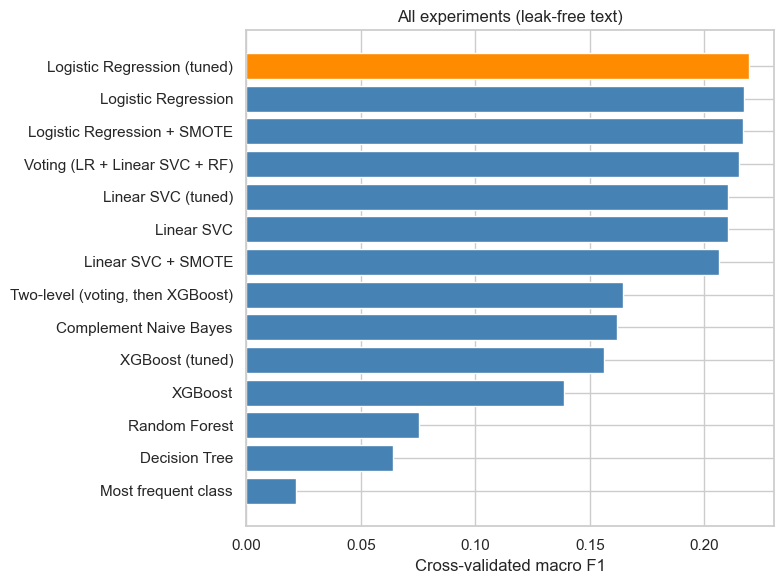

,Experiment,Model,CV accuracy,CV macro F1,Macro F1 std
0,3. Tuning,Logistic Regression (tuned),0.366,0.219,0.014
1,1. Model comparison,Logistic Regression,0.341,0.217,0.011
2,2. SMOTE,Logistic Regression + SMOTE,0.367,0.217,0.015
3,4. Voting,Voting (LR + Linear SVC + RF),0.335,0.215,0.009
4,1. Model comparison,Linear SVC,0.324,0.210,0.010
5,3. Tuning,Linear SVC (tuned),0.324,0.210,0.010
6,2. SMOTE,Linear SVC + SMOTE,0.333,0.206,0.013
7,5. Two-level,"Two-level (voting, then XGBoost)",0.337,0.164,0.013
8,1. Model comparison,Complement Naive Bayes,0.356,0.162,0.009
9,3. Tuning,XGBoost (tuned),0.312,0.156,0.014


In [11]:
summary = pd.DataFrame(results).sort_values('CV macro F1', ascending=False, ignore_index=True)
best_name = summary.loc[summary['Model'] != 'Most frequent class', 'Model'].iloc[0]
print(f'Selected model: {best_name}')

fig, ax = plt.subplots(figsize=(8, 6))
plot_data = summary.sort_values('CV macro F1')
ax.barh(plot_data['Model'], plot_data['CV macro F1'],
        color=['darkorange' if m == best_name else 'steelblue' for m in plot_data['Model']])
ax.set_xlabel('Cross-validated macro F1')
ax.set_title('All experiments (leak-free text)')
plt.tight_layout()
fig.savefig(FIG_DIR / 'experiments.png', dpi=150)
plt.show()
summary.round(3)

## 11. Final evaluation on the test set

In [12]:
estimator, weighted = models[best_name]
best_model = clone(estimator)
if weighted:
    best_model.fit(X_train, y_train, clf__sample_weight=train_weights)
else:
    best_model.fit(X_train, y_train)

pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, pred)
test_f1 = f1_score(y_test, pred, average='macro')
print(f'{best_name}')
print(f'Test accuracy: {test_acc:.3f}')
print(f'Test macro F1: {test_f1:.3f}\n')
print(classification_report(y_test, pred, target_names=encoder.classes_, zero_division=0))

Logistic Regression (tuned)
Test accuracy: 0.360
Test macro F1: 0.241

              precision    recall  f1-score   support

        ENFJ       0.27      0.29      0.28        38
        ENFP       0.28      0.36      0.31       135
        ENTJ       0.14      0.22      0.17        46
        ENTP       0.30      0.34      0.32       137
        ESFJ       0.00      0.00      0.00         9
        ESFP       0.00      0.00      0.00        10
        ESTJ       0.00      0.00      0.00         8
        ESTP       0.09      0.06      0.07        18
        INFJ       0.37      0.32      0.34       294
        INFP       0.51      0.44      0.47       366
        INTJ       0.33      0.34      0.33       218
        INTP       0.42      0.45      0.44       261
        ISFJ       0.24      0.24      0.24        33
        ISFP       0.22      0.30      0.25        54
        ISTJ       0.25      0.17      0.20        41
        ISTP       0.38      0.48      0.42        67

    accur

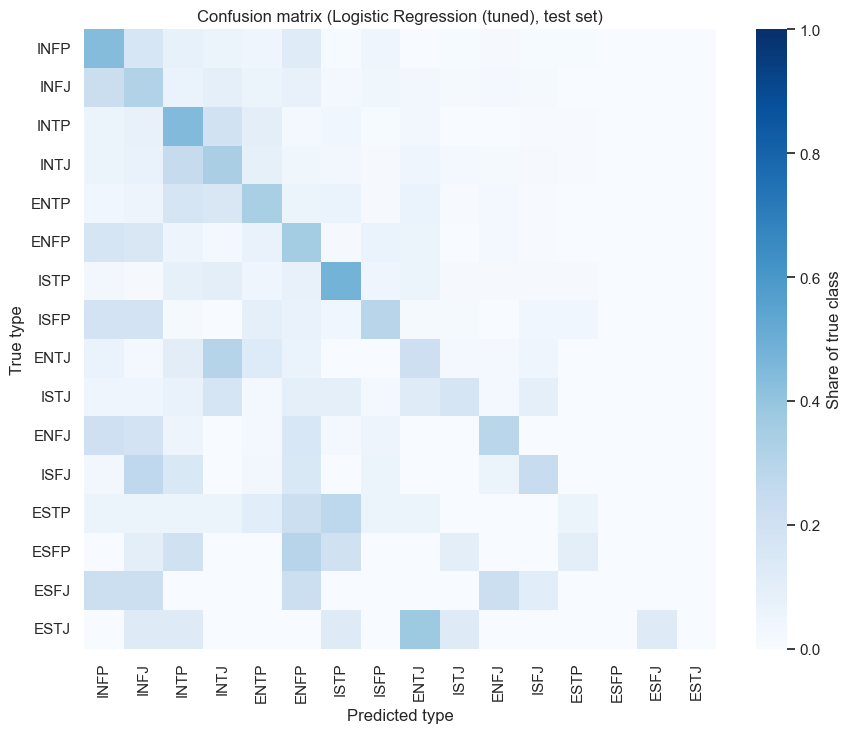

In [13]:
labels = counts.index.tolist()
cm = confusion_matrix(encoder.inverse_transform(y_test), encoder.inverse_transform(pred),
                      labels=labels, normalize='true')
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, xticklabels=labels, yticklabels=labels, cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Share of true class'})
ax.set_xlabel('Predicted type')
ax.set_ylabel('True type')
ax.set_title(f'Confusion matrix ({best_name}, test set)')
plt.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

## 12. How much did leakage inflate the results?

The selected model is trained again on text that still contains type names.

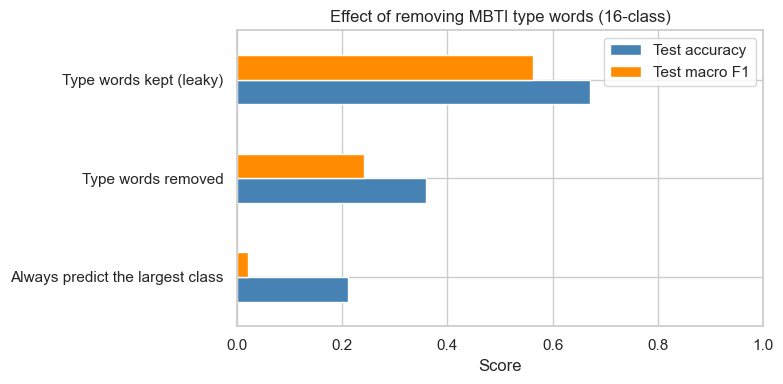

,Setting,Test accuracy,Test macro F1
0,Always predict the largest class,0.211,0.022
1,Type words removed,0.360,0.241
2,Type words kept (leaky),0.671,0.563


In [14]:
leaky_model = clone(estimator)
if weighted:
    leaky_model.fit(train.clean_leaky, y_train, clf__sample_weight=train_weights)
else:
    leaky_model.fit(train.clean_leaky, y_train)
leaky_pred = leaky_model.predict(test.clean_leaky)
baseline_pred = np.full(len(test), encoder.transform([counts.index[0]])[0])

comparison = pd.DataFrame({
    'Setting': ['Always predict the largest class', 'Type words removed', 'Type words kept (leaky)'],
    'Test accuracy': [accuracy_score(y_test, baseline_pred), test_acc, accuracy_score(y_test, leaky_pred)],
    'Test macro F1': [f1_score(y_test, baseline_pred, average='macro'), test_f1,
                      f1_score(y_test, leaky_pred, average='macro')],
})

fig, ax = plt.subplots(figsize=(8, 4))
comparison.set_index('Setting').plot.barh(ax=ax, color=['steelblue', 'darkorange'])
ax.set_xlim(0, 1)
ax.set_xlabel('Score')
ax.set_ylabel('')
ax.set_title('Effect of removing MBTI type words (16-class)')
plt.tight_layout()
fig.savefig(FIG_DIR / 'leakage_comparison.png', dpi=150)
plt.show()
comparison.round(3)

## 13. Predicting each MBTI dimension separately

MBTI types combine four binary dimensions. Predicting each one separately shows which aspects of personality
are reflected in writing. Balanced accuracy is used because the dimensions are imbalanced (for example,
77% of users are introverts).

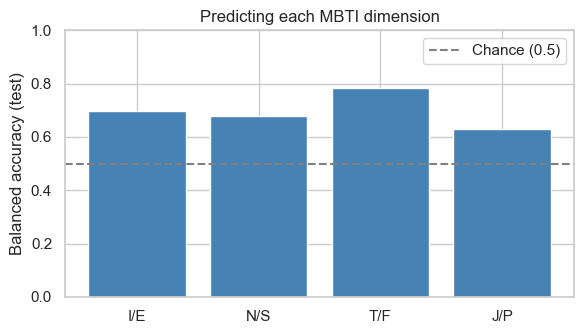

,Dimension,Majority share,Balanced accuracy
0,I/E,0.769,0.696
1,N/S,0.862,0.677
2,T/F,0.541,0.785
3,J/P,0.604,0.629


In [15]:
DIMENSIONS = {'I/E': 0, 'N/S': 1, 'T/F': 2, 'J/P': 3}
rows, dim_models = [], {}
for dim, pos in DIMENSIONS.items():
    dim_train = train.type.str[pos]
    dim_test = test.type.str[pos]
    model = make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced'))
    model.fit(X_train, dim_train)
    dim_models[dim] = model
    rows.append({'Dimension': dim,
                 'Majority share': dim_test.value_counts(normalize=True).iloc[0],
                 'Balanced accuracy': balanced_accuracy_score(dim_test, model.predict(X_test))})

dimensions = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dimensions.Dimension, dimensions['Balanced accuracy'], color='steelblue')
ax.axhline(0.5, color='gray', linestyle='--', label='Chance (0.5)')
ax.set_ylim(0, 1)
ax.set_ylabel('Balanced accuracy (test)')
ax.set_title('Predicting each MBTI dimension')
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'dimensions.png', dpi=150)
plt.show()
dimensions.round(3)

## 14. Most informative words for each dimension

The largest logistic regression coefficients show which words push the prediction toward each side.

In [16]:
rows = []
for dim, model in dim_models.items():
    words = model.named_steps['tfidf'].get_feature_names_out()
    clf = model.named_steps['clf']
    order = np.argsort(clf.coef_[0])
    first, second = clf.classes_
    rows.append({'Dimension': dim,
                 'Words toward first letter': f"{first}: " + ', '.join(words[order[:8]]),
                 'Words toward second letter': f"{second}: " + ', '.join(words[order[-8:][::-1]])})

pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows)

,Dimension,Words toward first letter,Words toward second letter
0,I/E,"E: sx, fun, bored, crazy, guys, awesome, super, xd","I: games, family, quiet, wish, anime, nature, lyrics, listening"
1,N/S,"N: world, ideas, dark, human, universe, books, fact, heart","S: rant, type, rave, inferior, fun, mbti, car, teddy"
2,T/F,"F: feel, love, values, feeling, beautiful, heart, xd, happy","T: female, boring, knowledge, fucking, stupid, bored, shit, forum"
3,J/P,"J: plan, cold, intuition, help, dear, plans, hsp, door","P: lazy, fuck, pretty, love, theories, really, weed, fun"


## 15. Conclusions

- **Leakage was the main source of the original accuracy.** 90% of users mention their own type. With the
  selected model, removing type words drops test accuracy from 67.1% to 36.0% and macro F1 from 0.563 to 0.241.
  The leak-free model is still well above the 21.1% majority baseline, so writing style does carry some signal.
- **Simple linear models work best.** Tuned logistic regression (C = 3) has the highest cross-validated macro F1
  (0.219). Plain logistic regression, voting, and Linear SVC are within 0.01 of it, so the extra complexity of
  voting does not help.
- **SMOTE does not improve on class weights** (logistic regression 0.217 vs. 0.217; Linear SVC 0.206 vs. 0.210),
  while making training slower.
- **Tree models fall far behind on leak-free text.** XGBoost reaches 0.139 (0.156 after tuning), random forest
  0.076, and a single decision tree 0.064. In the original notebook XGBoost was among the best models, likely
  because type words such as "infj" make very clean tree splits; once they are removed, the remaining signal is
  spread thinly over many words, which suits linear models better.
- **Two-level classification does not help.** It reaches a macro F1 of 0.164. Its first level predicts the four
  temperament groups with 68.8% accuracy (largest group 48.0%), compared with 74.4% in the original notebook,
  where type words were still present.
- **Rare types are hardest.** ESFJ, ESFP, and ESTJ have fewer than 10 test users each and are never predicted
  correctly, while INFP, INTP, and ISTP reach F1 above 0.4.
- **Thinking vs. Feeling is the most predictable dimension** (balanced accuracy 0.785), followed by I/E (0.696),
  N/S (0.677), and J/P (0.629). Feeling types use words like *feel*, *love*, and *values*; introverts mention
  *games*, *family*, *quiet*, and *nature*.
- **Some MBTI vocabulary remains** (for example *intuition*, *inferior*, *mbti*, *sx*), so a small amount of
  forum-specific signal is still present after cleaning.